# Parsing

In [ ]:
pip install scapy

In [ ]:
import os

#list EVERY dataset folder path needed to pull capture files from
#if everything is in 1 dataset, just list that 1 path

#COPY YOUR PATH INTO THE LIST AS SHOWN IN EXAMPLE
dataset_paths = [
#    "/datasets/pcaps-data/VPN-PCAPS-01",
#    "/datasets/pcaps-data/VPN-PCAPs-02",

]


capture_files = []

for dataset_path in dataset_paths:
    for root, dirs, files in os.walk(dataset_path):
        for f in files:
            if f.endswith(".pcap") or f.endswith(".pcapng"):
                capture_files.append(os.path.join(root, f))

print(f"\ntotal capture files found: {len(capture_files)}")

In [ ]:
#check for duplicate files
from collections import Counter

filenames_only = [os.path.basename(f) for f in capture_files]
name_counts = Counter(filenames_only)

duplicates = {name: count for name, count in name_counts.items() if count > 1}
print(f"duplicate filenames found: {len(duplicates)}")
if duplicates:
    print(duplicates)

In [ ]:
#functions to get the label and stream id from a filename
#and the PCAP parsing function
import re
from scapy.all import PcapReader, IP, TCP, UDP

def get_stream_id(filename):
    name = filename.replace(".pcapng", "").replace(".pcap", "") #pcapng first if not it wont be replaced correctly
    match = re.match(r"^(.*)([a-zA-Z])$", name)
    if match and re.search(r"\d[a-zA-Z]$", name):
        stream_id = match.group(1)
        part = match.group(2)
    else:
        stream_id = name
        part = None
    return stream_id, part

#reads filename and assigns network and category
def get_label(filename, network_type):
    name = filename.lower()

    #activity type
    #video here means LIVE video
    #streaming means the regular non live video
    categories = {
        "chat": ["chat"],
        "email": ["email", "gmail", "mail", "thunderbird", "imap", "pop"],
        "audio": ["audio", "voip", "voipbuster", "voice"],
        "video": ["video"], 
        "file_transfer": ["ftp", "ftps", "sftp", "scp", "skype_file", "skypefile", "filetransfer", "skype_transfer"],
        "p2p": ["torrent", "bittorrent", "p2p"],
        "streaming": ["spotify", "youtube", "netflix", "vimeo"],
        "browsing": ["browsing", "facebook", "google", "twitter", "ssl"]
    }

    category = "unknown"
    for cat, keywords in categories.items():
        if any(k in name for k in keywords):
            category = cat
            break

    return network_type, category
    
#PCAP parsing function
def parse_pcap_to_flows(filepath):
    flows = {}
    with PcapReader(filepath) as pcap_reader:
        for pkt in pcap_reader:
            if IP not in pkt:
                continue
            if TCP in pkt:
                proto = "TCP"
                sport = pkt[TCP].sport
                dport = pkt[TCP].dport
            elif UDP in pkt:
                proto = "UDP"
                sport = pkt[UDP].sport
                dport = pkt[UDP].dport
            else:
                continue

            src_ip = pkt[IP].src
            dst_ip = pkt[IP].dst

            if (src_ip, sport) < (dst_ip, dport):
                flow_key = (src_ip, sport, dst_ip, dport, proto)
                direction = 1
            else:
                flow_key = (dst_ip, dport, src_ip, sport, proto)
                direction = -1

            pkt_size = len(pkt)
            pkt_time = float(pkt.time)

            if flow_key not in flows:
                flows[flow_key] = []
            flows[flow_key].append((pkt_time, pkt_size, direction))

    return flows

In [ ]:
import os
import gc
import pickle

os.makedirs("parsed_flows", exist_ok=True)

#CHECK B4 RUNNING
NETWORK_TYPE = "" 

processed_count = 0
skipped_count = 0
failed_count = 0

for filepath in capture_files:
    filename = os.path.basename(filepath)
    safe_name = filename.replace(".", "_")
    out_path = f"parsed_flows/{safe_name}.pkl"

    if os.path.exists(out_path):
        skipped_count += 1
        continue

    stream_id, part = get_stream_id(filename)
    network_type, category = get_label(filename, network_type=NETWORK_TYPE)

    try:
        file_flows = parse_pcap_to_flows(filepath)
    except Exception as e:
        print(f"failed on {filename}: {e}")
        failed_count += 1
        continue

    file_records = []
    for flow_key, packet_seq in file_flows.items():
        file_records.append({
            "filepath": filepath,
            "filename": filename,
            "stream_id": stream_id,
            "part": part,
            "network_type": network_type,
            "category": category,
            "flow_key": flow_key,
            "packet_seq": packet_seq
        })

    with open(out_path, "wb") as f:
        pickle.dump(file_records, f)

    print(f"done: {filename} -> {len(file_records)} flows")
    processed_count += 1

    del file_flows, file_records
    gc.collect()

print(f"\nbatch complete: {NETWORK_TYPE}")
print(f"newly processed: {processed_count}")
print(f"skipped (already done): {skipped_count}")
print(f"failed: {failed_count}")
print(f"total files in capture_files: {len(capture_files)}")

In [ ]:
#see which files labelled as unknown
unknown_files = df[df["category"] == "unknown"]["filename"].unique()
print(unknown_files)

In [ ]:
import glob
import pandas as pd

#only combine the pickles belonging to files from THIS batch's capture_files
#matches by filename, so it only picks up what was just parsed in this run
batch_filenames = set(os.path.basename(f) for f in capture_files)

batch_records = []
for pkl_path in glob.glob("parsed_flows/*.pkl"):
    with open(pkl_path, "rb") as f:
        file_records = pickle.load(f)
        if file_records and file_records[0]["filename"] in batch_filenames:
            batch_records.extend(file_records)

df = pd.DataFrame(batch_records)
print(f"total flows in this batch ({NETWORK_TYPE}): {len(df)}")
print(df["category"].value_counts())

#save this batch's dataframe with a name based on its network type
df.to_pickle(f"nonvpn2_files_AL2.pkl")

In [ ]:
first_row = df.iloc[0]
for col in df.columns:
    if col == "packet_seq":
        print(f"{col}: {first_row[col][:5]} ... ({len(first_row[col])} total packets)")
    else:
        print(f"{col}: {first_row[col]}")

# Loading parsed files in

In [4]:
import pandas as pd

#load every saved batch back in
#load YOUR own .pkl files as shown in the example
non_vpn1 = pd.read_pickle("/data/nonvpn1_files_AL2.pkl")
non_vpn2 = pd.read_pickle("")
non_vpn3 = pd.read_pickle("")
vpn = pd.read_pickle("")
tor = pd.read_pickle("")

#combine into one dataframe
df_combined = pd.concat([non_vpn1, non_vpn2, non_vpn3, vpn, tor], ignore_index=True)

print(f"total combined flows: {len(df_combined)}")

#save the final combined dataset
#you can save it in 1 file if you wish
#df_combined.to_pickle("combined_flows.pkl")

print(f"shape: {df_combined.shape}")

#percentage distribution of network_type
print(df_combined["network_type"].value_counts(normalize=True) * 100)
print()

#percentage distribution of category
print(df_combined["category"].value_counts(normalize=True) * 100)

df_combined.head(3)

total combined flows: 188670
shape: (188670, 8)
network_type
non_vpn    89.884454
vpn         9.418031
tor         0.697514
Name: proportion, dtype: float64

category
audio            65.933641
file_transfer    21.262522
chat              6.302009
email             2.912493
streaming         1.423650
video             1.327715
p2p               0.817300
browsing          0.020671
Name: proportion, dtype: float64


,filepath,filename,stream_id,part,network_type,category,flow_key,packet_seq
0,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.93, 57806, 255.255.255.255, 10505...","[(1432572763.37583, 127, 1)]"
1,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.183, 63970, 255.255.255.255, 1900...","[(1432572763.491782, 215, 1), (1432572763.4919..."
2,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.117, 54995, 255.255.255.255, 1050...","[(1432572763.515294, 131, 1)]"


In [ ]:
first_row = df_combined.iloc[0]
for col in df_combined.columns:
    if col == "packet_seq":
        print(f"{col}: {first_row[col][:5]} ... ({len(first_row[col])} total packets)")
    else:
        print(f"{col}: {first_row[col]}")

# Cleaning

In [6]:
def get_flow_duration(packet_seq):
    if len(packet_seq) < 2: #need min 2 packets to find difference
        return 0 
    timestamps = [p[0] for p in packet_seq]
    return max(timestamps) - min(timestamps)

#duration of flow
df_combined["flow_duration"] = df_combined["packet_seq"].apply(get_flow_duration)

print("description")
print(df_combined["flow_duration"].describe())
print()
print("quantile")
print(df_combined["flow_duration"].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 1.0]))
print()
print("bins")
print(df_combined["flow_duration"].value_counts(bins=20).sort_index())

description
count    188670.000000
mean        252.848853
std         798.185257
min           0.000000
25%           0.144604
50%           0.412059
75%           0.421085
max        6413.501714
Name: flow_duration, dtype: float64

quantile
0.50       0.412059
0.75       0.421085
0.90     746.812158
0.95    2126.450915
0.99    4076.028234
1.00    6413.501714
Name: flow_duration, dtype: float64

bins
(-6.415, 320.675]       165223
(320.675, 641.35]         3538
(641.35, 962.025]         2894
(962.025, 1282.7]         2286
(1282.7, 1603.375]        2189
(1603.375, 1924.051]      2014
(1924.051, 2244.726]      1701
(2244.726, 2565.401]      1666
(2565.401, 2886.076]      1397
(2886.076, 3206.751]      1228
(3206.751, 3527.426]      1117
(3527.426, 3848.101]       956
(3848.101, 4168.776]       751
(4168.776, 4489.451]       570
(4489.451, 4810.126]       435
(4810.126, 5130.801]       350
(5130.801, 5451.476]       194
(5451.476, 5772.152]        79
(5772.152, 6092.827]        78
(6092.8

In [7]:
#number of packets in each flow
df_combined["packet_count"] = df_combined["packet_seq"].apply(len)

print("description")
print(df_combined["packet_count"].describe())
print()
print("quantile")
print(df_combined["packet_count"].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 1.0]))
print()
print("bins")
print(df_combined["packet_count"].value_counts(bins=20).sort_index())

description
count    1.886700e+05
mean     2.182734e+02
std      1.346167e+04
min      1.000000e+00
25%      2.000000e+00
50%      2.000000e+00
75%      2.000000e+00
max      2.951457e+06
Name: packet_count, dtype: float64

quantile
0.50          2.0
0.75          2.0
0.90          4.0
0.95          6.0
0.99         71.0
1.00    2951457.0
Name: packet_count, dtype: float64

bins
(-2950.4570000000003, 147573.8]    188615
(147573.8, 295146.6]                   18
(295146.6, 442719.4]                   15
(442719.4, 590292.2]                    8
(590292.2, 737865.0]                    3
(737865.0, 885437.8]                    2
(885437.8, 1033010.6]                   2
(1033010.6, 1180583.4]                  0
(1180583.4, 1328156.2]                  0
(1328156.2, 1475729.0]                  5
(1475729.0, 1623301.8]                  0
(1623301.8, 1770874.6]                  0
(1770874.6, 1918447.4]                  0
(1918447.4, 2066020.2]                  0
(2066020.2, 2213593.0]        

In [8]:
#from above, most packets fall into first bin.
#find the number of flows that contain each packet, up to 20
print(df_combined["packet_count"].value_counts().sort_index().head(20))

packet_count
1      20923
2     133819
3        650
4      19807
5        234
6       4165
7        454
8        852
9        249
10       569
11       249
12       299
13       297
14       214
15       287
16       163
17       189
18       181
19       202
20       171
Name: count, dtype: int64


In [9]:
#see how the duration is like for packet_count >=5
df_packet_filtered = df_combined[df_combined["packet_count"] >= 5]
print(df_packet_filtered["flow_duration"].describe())
print()
print(df_packet_filtered["flow_duration"].quantile([0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 1]))

count    13471.000000
mean      1111.686472
std       1526.169041
min          0.000846
25%          8.394011
50%        220.760416
75%       2037.051153
max       6413.501714
Name: flow_duration, dtype: float64

0.05       0.159927
0.10       0.485169
0.25       8.394011
0.50     220.760416
0.75    2037.051153
0.90    3634.037921
1.00    6413.501714
Name: flow_duration, dtype: float64


In [10]:
#the packet_count filter removed a lot of the flows with very low duration
#so dont need to filter noise from duration
MIN_PACKETS = 5 #spike at packet 2 and 4. so set min=5 to remove those noise
MIN_DURATION = 1.0 #set this to 1. duration < 1 has no meaningful temporal data

df_clean = df_combined[(df_combined["packet_count"] >= MIN_PACKETS) & (df_combined["flow_duration"] >= MIN_DURATION)].copy()

print(f"before: {len(df_combined)}, after: {len(df_clean)}")
print()
print(df_clean["flow_duration"].describe())
print()
print(df_clean["flow_duration"].quantile([0.5, 0.60, 0.65, 0.70, 0.75, 0.8, 0.85, 0.90, 0.95, 0.99, 1.0]))

before: 188670, after: 11885

count    11885.000000
mean      1260.000541
std       1566.265065
min          1.000637
25%         33.422062
50%        381.199485
75%       2343.469820
max       6413.501714
Name: flow_duration, dtype: float64

0.50     381.199485
0.60     914.059164
0.65    1333.833149
0.70    1865.763452
0.75    2343.469820
0.80    2785.737009
0.85    3300.295459
0.90    3814.513671
0.95    4471.033657
0.99    5521.663819
1.00    6413.501714
Name: flow_duration, dtype: float64


In [11]:
#percentage distribution of network_type
print(df_clean["network_type"].value_counts(normalize=True) * 100)
print()

#percentage distribution of category
print(df_clean["category"].value_counts(normalize=True) * 100)

network_type
non_vpn    80.504838
vpn        16.752209
tor         2.742953
Name: proportion, dtype: float64

category
audio            45.460665
file_transfer    23.281447
streaming        11.922592
chat              6.571308
email             4.997897
video             3.920909
p2p               3.584350
browsing          0.260833
Name: proportion, dtype: float64


In [12]:
#duration by category and network
print("=== duration by category ===")
display(df_clean.groupby("category")["flow_duration"].describe())

print("\n=== duration by network_type ===")
display(df_clean.groupby("network_type")["flow_duration"].describe())


#results:
#CATEGORY
#audio dominates, as expected
#chat, email, video, p2p, streaming on shorter side
#browsing, email, file_transfer, p2p, video have much larger avg than median: few extreme outliers to pull them up

#NETWORK
#non_vpn longest, followed by tor and vpn

=== duration by category ===


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
audio,5403.0,2149.549269,1707.408962,1.009895,318.289979,2100.363737,3509.352972,6375.836560
browsing,31.0,1077.745105,1351.671791,1.218211,189.011474,302.327444,1700.318048,4902.175732
chat,781.0,381.428095,355.036338,1.024936,59.274782,240.235541,690.690448,1336.179729
email,594.0,372.859022,866.920590,1.007133,2.518546,6.364699,501.741219,5619.325462
file_transfer,2767.0,871.295257,1186.543701,1.032077,6.108362,116.423438,1612.493256,5002.507509
p2p,426.0,90.828261,532.066458,1.070224,2.425793,7.085809,20.179125,6413.501714
streaming,1417.0,170.618714,381.543803,1.000637,17.843951,83.807249,210.852744,6375.836560
video,466.0,251.018222,422.152350,1.014952,11.670427,65.333111,283.712605,3703.812379



=== duration by network_type ===


,count,mean,std,min,25%,50%,75%,max
network_type,,,,,,,,
non_vpn,9568.0,1464.748873,1619.862151,1.005867,60.820939,669.008383,2638.406671,5886.010418
tor,326.0,513.490014,1124.441308,1.000637,2.315480,90.137115,404.691567,6413.501714
vpn,1991.0,398.288027,890.538931,1.009895,8.959246,59.190987,214.875712,4116.135039


In [13]:
#bytes by category
#sanity check: streaming/video/file transfer should be larger than chat/email
def get_total_bytes(packet_seq):
    return sum(p[1] for p in packet_seq)

df_clean["total_bytes"] = df_clean["packet_seq"].apply(get_total_bytes)

display(df_clean.groupby("category")["total_bytes"].describe())

#results
#browsing, file_transfer, streaming have very large skews
#investigated them, SEEMS genuine skew rather than mistake

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
audio,5403.0,3.470441e+05,4.932894e+06,260.0,384.00,452.0,2492.00,1.313403e+08
browsing,31.0,1.749849e+07,3.585700e+07,594.0,11483.00,626238.0,15899292.50,1.328807e+08
chat,781.0,8.286054e+04,3.756707e+05,240.0,1792.00,4692.0,10040.00,3.922199e+06
email,594.0,5.742318e+05,6.880396e+06,315.0,3119.25,4469.0,5241.25,1.096181e+08
file_transfer,2767.0,7.850504e+06,9.046630e+07,294.0,384.00,660.0,5545.00,2.430622e+09
p2p,426.0,1.268841e+07,1.192707e+08,270.0,6896.00,644095.5,1388242.75,1.296150e+09
streaming,1417.0,2.510632e+06,2.581639e+07,282.0,660.00,1615.0,8479.00,7.850586e+08
video,466.0,1.201392e+07,8.105671e+07,300.0,1250.00,3413.5,11958.75,1.191458e+09


In [ ]:
#sanity check: 1 stream_id : 1 category
#return empty list if everything is correct

inconsistent = df_clean.groupby("stream_id")["category"].nunique()
print(inconsistent[inconsistent > 1])

In [11]:
#find the duration at which each category reaches ~90% coverage
print("category")
for cat in df_clean["category"].unique():
    cat_durations = df_clean[df_clean["category"] == cat]["flow_duration"]
    p90 = cat_durations.quantile(0.90)
    print(f"{cat}: 90% coverage at {p90:.0f}s")

print("\nnetwork_type")
#find the duration at which each network_type reaches ~90% coverage
for nt in df_clean["network_type"].unique():
    nt_durations = df_clean[df_clean["network_type"] == nt]["flow_duration"]
    p90 = nt_durations.quantile(0.90)
    print(f"{nt}: 90% coverage at {p90:.0f}s")

print()
#coverage at 3000s, grouped by network_type
for nt in df_clean["network_type"].unique():
    nt_durations = df_clean[df_clean["network_type"] == nt]["flow_duration"]
    coverage = (nt_durations <= 3000).mean() * 100
    print(f"{nt}: {coverage:.1f}% coverage at 3000s")

category
email: 90% coverage at 597s
audio: 90% coverage at 4549s
video: 90% coverage at 580s
chat: 90% coverage at 933s
file_transfer: 90% coverage at 2857s
streaming: 90% coverage at 262s
p2p: 90% coverage at 117s
browsing: 90% coverage at 2858s

network_type
non_vpn: 90% coverage at 4023s
vpn: 90% coverage at 1262s
tor: 90% coverage at 1146s

non_vpn: 79.0% coverage at 3000s
vpn: 94.4% coverage at 3000s
tor: 93.9% coverage at 3000s


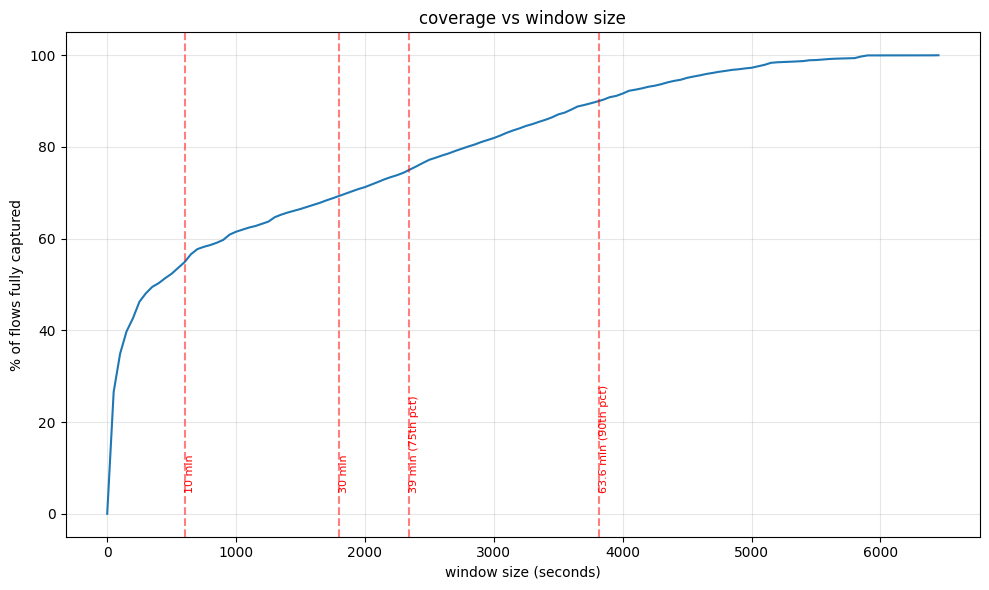

In [12]:
import matplotlib.pyplot as plt
import numpy as np

#compute coverage percentage for a range of window sizes
#see if there's any elbow to determine coverage for bucket
window_range = np.arange(0, 6500, 50)  #every 50 seconds, from 0 to max duration
coverage = [(df_clean["flow_duration"] <= w).mean() * 100 for w in window_range]

plt.figure(figsize=(10, 6))
plt.plot(window_range, coverage)
plt.xlabel("window size (seconds)")
plt.ylabel("% of flows fully captured")
plt.title("coverage vs window size")
plt.grid(True, alpha=0.3)

#mark candidate options for reference
for w, label in [(600, "10 min"), (1800, "30 min"), (2343, "39 min (75th pct)"), (3814, "63.6 min (90th pct)")]:
    plt.axvline(x=w, color="red", linestyle="--", alpha=0.5)
    plt.text(w, 5, label, rotation=90, fontsize=8, color="red")

plt.tight_layout()
#plt.savefig("coverage_vs_window.png", dpi=150, bbox_inches="tight")
plt.show()

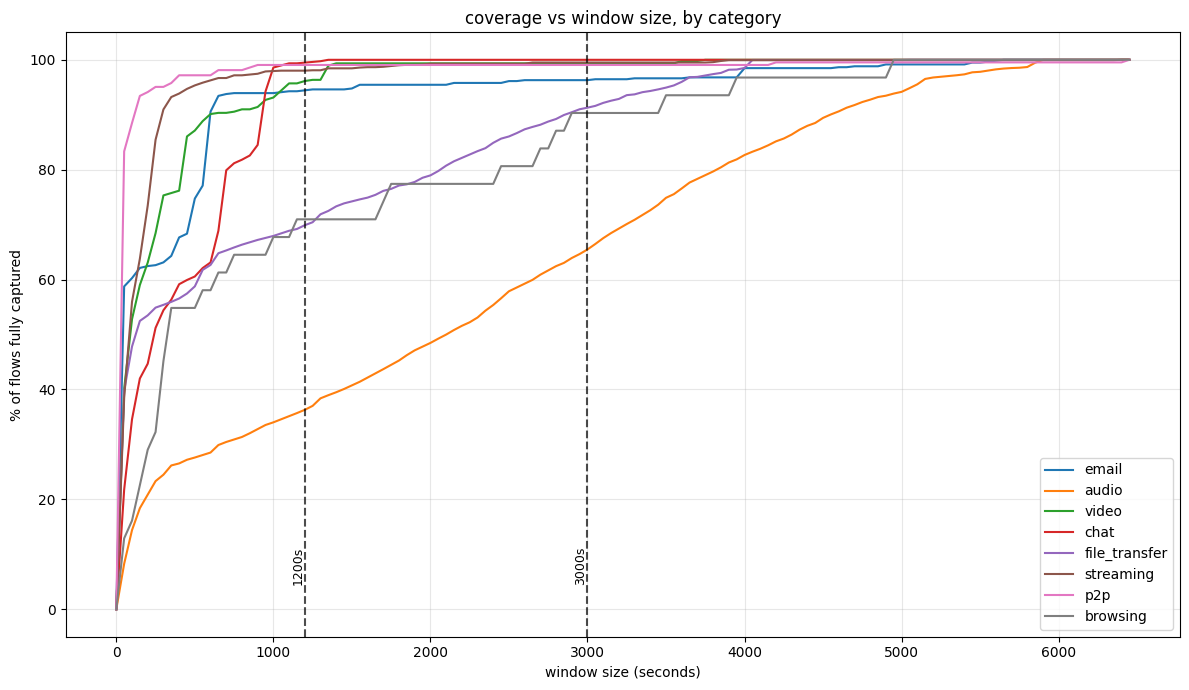

In [13]:
#coverage curve, but broken down by category
window_range = np.arange(0, 6500, 50)

plt.figure(figsize=(12, 7))
for cat in df_clean["category"].unique():
    cat_durations = df_clean[df_clean["category"] == cat]["flow_duration"]
    coverage = [(cat_durations <= w).mean() * 100 for w in window_range]
    plt.plot(window_range, coverage, label=cat)

plt.xlabel("window size (seconds)")
plt.ylabel("% of flows fully captured")
plt.title("coverage vs window size, by category")
plt.legend()
plt.grid(True, alpha=0.3)

#add the 1200s and 3000s reference line
plt.axvline(x=1200, color="black", linestyle="--", alpha=0.7, label="candidate window (1200s)")
plt.axvline(x=3000, color="black", linestyle="--", alpha=0.7, label="candidate window (3000s)")
plt.text(1200, 5, "1200s", rotation=90, fontsize=9, color="black", ha="right")
plt.text(3000, 5, "3000s", rotation=90, fontsize=9, color="black", ha="right")

plt.tight_layout()
#plt.savefig("coverage_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

#just choose 3000s as coverage for bucketing

# Bucketing

In [16]:
import numpy as np

#ADJUST THE BUCKETS
#50 * 60 = 3000 seconds coverage
BUCKET_SIZE_SECONDS = 60
NUM_BUCKETS = 50 

#bytes sent and received per bucket
def bucket_bytes_by_direction(packet_seq, bucket_size=BUCKET_SIZE_SECONDS, num_buckets=NUM_BUCKETS):
    if len(packet_seq) == 0:
        return np.zeros(num_buckets * 2)

    flow_start = packet_seq[0][0]
    bytes_out = np.zeros(num_buckets)
    bytes_in = np.zeros(num_buckets)

    for timestamp, size, direction in packet_seq:
        elapsed = timestamp - flow_start
        bucket_index = int(elapsed // bucket_size)
        if bucket_index < num_buckets:
            if direction > 0:
                bytes_out[bucket_index] += size
            else:
                bytes_in[bucket_index] += size

    return np.concatenate([bytes_out, bytes_in])

#packets sent and received per bucket
def bucket_packets_by_direction(packet_seq, bucket_size=BUCKET_SIZE_SECONDS, num_buckets=NUM_BUCKETS):
    if len(packet_seq) == 0:
        return np.zeros(num_buckets * 2)

    flow_start = packet_seq[0][0]
    packets_out = np.zeros(num_buckets)
    packets_in = np.zeros(num_buckets)

    for timestamp, size, direction in packet_seq:
        elapsed = timestamp - flow_start
        bucket_index = int(elapsed // bucket_size)
        if bucket_index < num_buckets:
            if direction > 0:
                packets_out[bucket_index] += 1
            else:
                packets_in[bucket_index] += 1

    return np.concatenate([packets_out, packets_in])

In [17]:
#apply and expand into columns: bytes_out_0...49, bytes_in_0...49
bytes_result = df_clean["packet_seq"].apply(bucket_bytes_by_direction)
bytes_cols = [f"bytes_out_{i}" for i in range(NUM_BUCKETS)] + [f"bytes_in_{i}" for i in range(NUM_BUCKETS)]
df_bytes = pd.DataFrame(bytes_result.tolist(), columns=bytes_cols, index=df_clean.index)

#apply and expand into columns: packets_out_0...49, packets_in_0...49
packets_result = df_clean["packet_seq"].apply(bucket_packets_by_direction)
packets_cols = [f"packets_out_{i}" for i in range(NUM_BUCKETS)] + [f"packets_in_{i}" for i in range(NUM_BUCKETS)]
df_packets = pd.DataFrame(packets_result.tolist(), columns=packets_cols, index=df_clean.index)

In [18]:
print(f"before shape: {df_clean.shape}")

#combine with original columns
df_clean_features = pd.concat([df_clean, df_bytes, df_packets], axis=1)
print(f"after shape: {df_clean_features.shape}")
df_clean_features.head(3)

before shape: (11885, 11)
after shape: (11885, 211)


,filepath,filename,stream_id,part,network_type,category,flow_key,packet_seq,flow_duration,packet_count,...,packets_in_40,packets_in_41,packets_in_42,packets_in_43,packets_in_44,packets_in_45,packets_in_46,packets_in_47,packets_in_48,packets_in_49
1,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.183, 63970, 255.255.255.255, 1900...","[(1432572763.491782, 215, 1), (1432572763.4919...",556.737612,20,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.217, 5353, 224.0.0.251, 5353, UDP)","[(1432572763.944989, 86, 1), (1432572772.96247...",593.128556,10,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.183, 54357, 131.202.243.255, 3241...","[(1432572764.072761, 63, 1), (1432572769.07285...",604.998294,122,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [19]:
df_clean.columns

Index(['filepath', 'filename', 'stream_id', 'part', 'network_type', 'category',
       'flow_key', 'packet_seq', 'flow_duration', 'packet_count',
       'total_bytes'],
      dtype='object')

# EDA

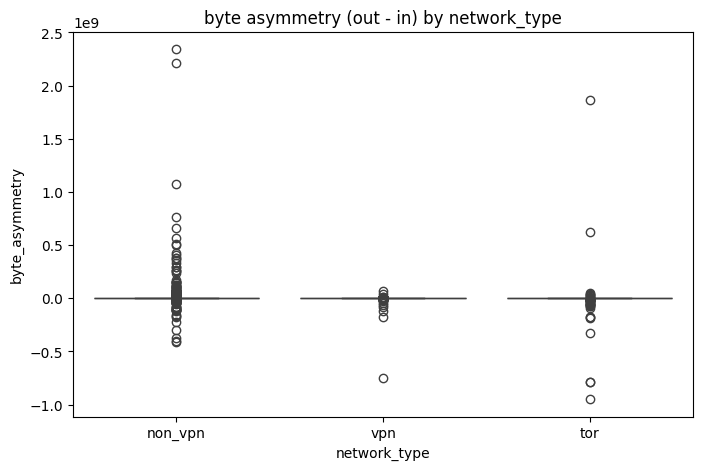

In [17]:
#asymmetry between bytes out and bytes in, across network_type
bytes_out_cols = [c for c in df_clean_features.columns if c.startswith("bytes_out_")]
bytes_in_cols = [c for c in df_clean_features.columns if c.startswith("bytes_in_")]

df_clean_features["total_bytes_out"] = df_clean_features[bytes_out_cols].sum(axis=1)
df_clean_features["total_bytes_in"] = df_clean_features[bytes_in_cols].sum(axis=1)
df_clean_features["byte_asymmetry"] = df_clean_features["total_bytes_out"] - df_clean_features["total_bytes_in"]

import seaborn as sns
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean_features, x="network_type", y="byte_asymmetry")
plt.title("byte asymmetry (out - in) by network_type")
plt.show()

#does seem to help distinguish network type

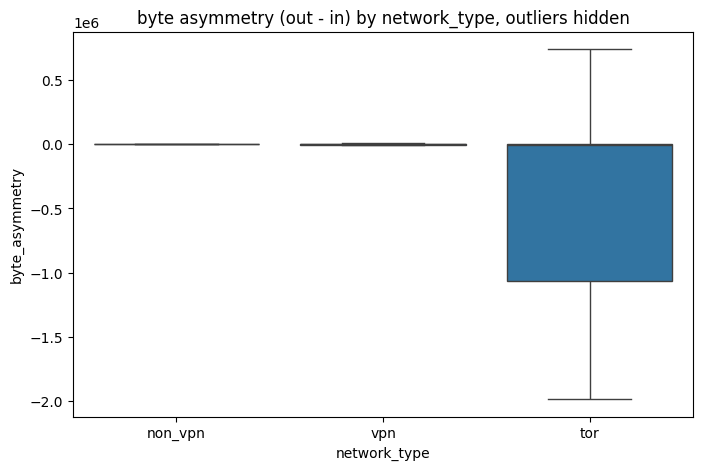

In [18]:
#boxplot with outliers hidden, so the box itself is visible
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean_features, x="network_type", y="byte_asymmetry", showfliers=False)
plt.title("byte asymmetry (out - in) by network_type, outliers hidden")
plt.show()

In [20]:
#precise stats, including iqr, for each network_type
df_clean_features.groupby("network_type")["byte_asymmetry"].describe()

#conclusion: splitting into bytes in and out does seem to help distinguish the network

,count,mean,std,min,25%,50%,75%,max
network_type,,,,,,,,
non_vpn,9568.0,1.323514e+06,4.074549e+07,-413166480.0,66.0,384.0,512.0,2.342573e+09
tor,326.0,-5.256213e+06,1.389414e+08,-948960659.0,-1069611.0,-4060.0,189.0,1.863731e+09
vpn,1991.0,-8.464563e+05,1.789160e+07,-753558407.0,-3667.0,45.0,570.0,6.842989e+07


count    11885.000000
mean        93.853176
std         11.455344
min          0.000000
25%         96.000000
50%         97.000000
75%         98.000000
max         99.000000
Name: zero_bucket_pct, dtype: float64


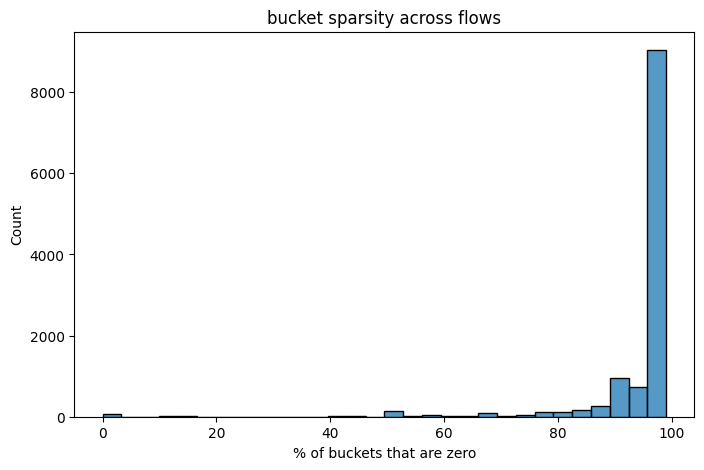

In [23]:
#sparsity check: % of buckets that are zero, per flow
feature_cols = bytes_out_cols + bytes_in_cols
zero_pct_per_flow = (df_clean_features[feature_cols] == 0).sum(axis=1) / len(feature_cols) * 100

df_clean_features["zero_bucket_pct"] = zero_pct_per_flow
print(df_clean_features["zero_bucket_pct"].describe())

plt.figure(figsize=(8, 5))
sns.histplot(df_clean_features["zero_bucket_pct"], bins=30)
plt.xlabel("% of buckets that are zero")
plt.title("bucket sparsity across flows")
plt.show()

In [25]:
#does sparsity differ meaningfully by network_type
df_clean_features.groupby("network_type")["zero_bucket_pct"].describe()

,count,mean,std,min,25%,50%,75%,max
network_type,,,,,,,,
non_vpn,9568.0,94.301108,9.949457,0.0,96.0,97.0,98.0,99.0
tor,326.0,87.478528,24.772401,0.0,92.0,96.0,98.0,99.0
vpn,1991.0,92.744350,14.095241,0.0,94.0,98.0,98.0,99.0


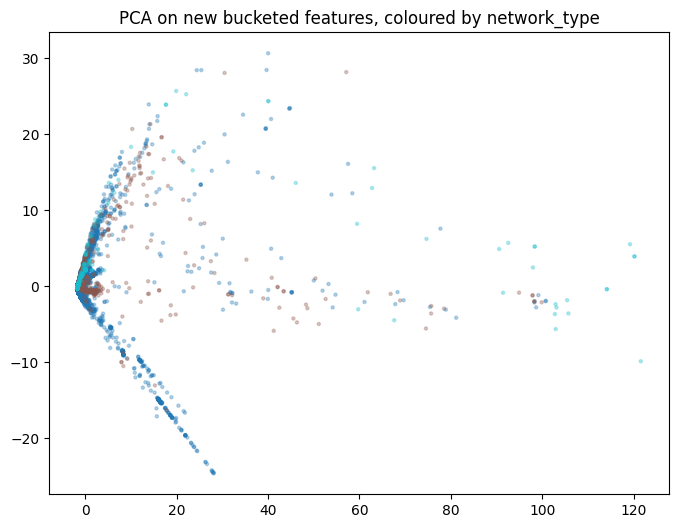

In [20]:
#PCA on the new bucketed feature matrix, coloured by network_type
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_new = df_clean_features[feature_cols].values
X_new_scaled = StandardScaler().fit_transform(np.log1p(X_new))

pca_new = PCA(n_components=2).fit_transform(X_new_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(pca_new[:, 0], pca_new[:, 1], c=pd.factorize(df_clean_features["network_type"])[0], cmap="tab10", s=5, alpha=0.3)
plt.title("PCA on new bucketed features, coloured by network_type")
plt.show()

In [ ]:
#the last 2 cells are "leftover code" from the previous version
#CHECKING DISTRIBUTION
all_values_clean = X_clean.flatten()
nonzero_values_clean = all_values_clean[all_values_clean > 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(nonzero_values_clean, bins=100)
axes[0].set_title("raw bucket values (nonzero) - cleaned")

axes[1].hist(np.log1p(nonzero_values_clean), bins=100)
axes[1].set_title("log1p-transformed bucket values - cleaned")

plt.tight_layout()
#plt.savefig("distribution_check_clean.png", dpi=150, bbox_inches="tight")
plt.show()

raw_skew_clean = skew(nonzero_values_clean)
log_skew_clean = skew(np.log1p(nonzero_values_clean))

print(f"skewness (raw, cleaned): {raw_skew_clean:.2f}")
print(f"skewness (log1p, cleaned): {log_skew_clean:.2f}")

In [ ]:
from sklearn.preprocessing import StandardScaler

#from results, use ln(1+x) then standardize. too much skew


#CLEANED data
X_clean_log = np.log1p(X_clean)  
scaler_clean = StandardScaler()
X_clean_scaled = scaler_clean.fit_transform(X_clean_log)

# Baseline